Studi kasus ini menguraikan mekanisme kerja jaringan saraf tiruan dalam mengklasifikasikan data klinis melalui tahapan berikut:
1. **Membedah dan Memahami Data Klinis:** Menganalisis 13 atribut dari pasien pada *Statlog (Heart) Dataset* (UCI Machine Learning Repository).
2. **Klarifikasi & Validasi Data:** Memverifikasi data dengan dokumentasi asli.
3. **Memahami Preprocessing Medis:** Membuktikan mengapa standardisasi fitur (*Z-score scaling*) diperlukan pada data disparsitas tinggi.
4. **Mengeksplorasi Arsitektur Output:** Membandingkan pendekatan **Single Output** vs **Multi Output**.
5. **Eksperimen Hyperparameter Terstruktur:** Melakukan *grid search* variasi *Hidden Units*, *Learning Rate* ($\mu$), dan *Epoch* dalam konteks konvergensi.
6. **Visualisasi Gradient Descent**.
7. **Evaluasi Error Ratio & Analisis:** Menghitung *Error Ratio* dan *Confusion Matrix*, dan mengambil kesimpulan medis dari kesalahan klasifikasi (*False Negative* vs *False Positive*).

## **1. Import Library & Setup Lingkungan**

In [25]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## **2. Load Dataset & Validasi Data**

Dataset yang digunakan bersumber dari **UCI Machine Learning Repository: Statlog (Heart) Dataset**.
Dataset ini memuat data medis dari **270 pasien** dengan **13 fitur** dan **1 kolom target**.

In [26]:
df = pd.read_csv("statlog.csv")

print(f"Dimensi Data (Shape) : {df.shape[0]} baris (pasien) × {df.shape[1]} kolom")

print("\nHead:")
display(df.head())

print("\nTail:")
display(df.tail())

Dimensi Data (Shape) : 270 baris (pasien) × 14 kolom

Head:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,presence
0,70.0,1.0,4.0,130.0,322.0,0.0,2.0,109.0,0.0,2.4,2.0,3.0,3.0,2
1,67.0,0.0,3.0,115.0,564.0,0.0,2.0,160.0,0.0,1.6,2.0,0.0,7.0,1
2,57.0,1.0,2.0,124.0,261.0,0.0,0.0,141.0,0.0,0.3,1.0,0.0,7.0,2
3,64.0,1.0,4.0,128.0,263.0,0.0,0.0,105.0,1.0,0.2,2.0,1.0,7.0,1
4,74.0,0.0,2.0,120.0,269.0,0.0,2.0,121.0,1.0,0.2,1.0,1.0,3.0,1



Tail:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,presence
265,52.0,1.0,3.0,172.0,199.0,1.0,0.0,162.0,0.0,0.5,1.0,0.0,7.0,1
266,44.0,1.0,2.0,120.0,263.0,0.0,0.0,173.0,0.0,0.0,1.0,0.0,7.0,1
267,56.0,0.0,2.0,140.0,294.0,0.0,2.0,153.0,0.0,1.3,2.0,0.0,3.0,1
268,57.0,1.0,4.0,140.0,192.0,0.0,0.0,148.0,0.0,0.4,2.0,0.0,6.0,1
269,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2


## **3. Penjelasan Atribut Medis**

| No | Kode Kolom | Nama Medis Asli | Tipe Data | Domain Nilai | Keterangan Klinis |
|:--:|:-----------|:----------------|:----------|:-------------|:-------------------|
| 1 | `age` ($a_1$) | Age | Numerik | 29 s.d. 77 tahun | Usia pasien saat pemeriksaan rekam medis. |
| 2 | `sex` ($a_2$) | Sex / Gender | Biner | 0 = Wanita, 1 = Pria | Jenis kelamin pasien. |
| 3 | `cp` ($a_3$) | Chest Pain Type | Nominal | 1, 2, 3, 4 | 1: Typical angina, 2: Atypical angina, 3: Non-anginal pain, 4: Asymptomatic (tanpa gejala khas). |
| 4 | `trestbps` ($a_4$) | Resting Blood Pressure | Numerik | 94 s.d. 200 mmHg | Tekanan darah sistolik saat pasien beristirahat di klinik. |
| 5 | `chol` ($a_5$) | Serum Cholestoral | Numerik | 126 s.d. 564 mg/dl | Kadar kolesterol total dalam serum darah pasien. |
| 6 | `fbs` ($a_6$) | Fasting Blood Sugar | Biner | 0: $\le 120$, 1: $> 120$ mg/dl | Indikator gula darah puasa (menandakan potensi diabetes). |
| 7 | `restecg` ($a_7$) | Resting ECG Results | Nominal | 0, 1, 2 | 0: Normal, 1: Kelainan gelombang ST-T, 2: Hipertrofi ventrikel kiri. |
| 8 | `thalach` ($a_8$) | Maximum Heart Rate | Numerik | 71 s.d. 202 bpm | Denyut jantung maksimum yang berhasil dicapai pasien saat tes stres latihan. |
| 9 | `exang` ($a_9$) | Exercise Induced Angina | Biner | 0 = Tidak, 1 = Ya | Apakah timbul nyeri dada angina saat dipicu aktivitas fisik. |
| 10 | `oldpeak` ($a_{10}$) | ST Depression | Numerik | 0.0 s.d. 6.2 | Penurunan segmen ST yang dipicu latihan relatif terhadap kondisi istirahat. |
| 11 | `slope` ($a_{11}$) | Slope of Peak ST | Ordinal | 1, 2, 3 | Kemiringan segmen ST: 1: Upsloping, 2: Flat, 3: Downsloping. |
| 12 | `ca` ($a_{12}$) | Number of Major Vessels | Numerik | 0 s.d. 3 pembuluh | Jumlah pembuluh darah utama (0-3) yang diwarnai fluoroskopi. |
| 13 | `thal` ($a_{13}$) | Thallium Heart Scan | Nominal | 3, 6, 7 | Hasil scan perfusi thallium: 3: Normal, 6: Fixed defect, 7: Reversable defect. |
| **14** | **`presence`** | **Heart Disease Target** | **Target** | **1, 2** | **1: Absence (Tidak ada penyakit jantung / Sehat)**<br>**2: Presence (Terdeteksi penyakit jantung / Sakit)** |


In [27]:
class_counts = df['presence'].value_counts().sort_index()

print("Distribusi Kelas Pasien:")
print(f"  Kelas 1 (Absence / Sehat) : {class_counts[1]} pasien ({class_counts[1]/len(df)*100:.2f}%)")
print(f"  Kelas 2 (Presence / Sakit): {class_counts[2]} pasien ({class_counts[2]/len(df)*100:.2f}%)")
print(f"  Total Observasi Pasien    : {len(df)} pasien")

Distribusi Kelas Pasien:
  Kelas 1 (Absence / Sehat) : 150 pasien (55.56%)
  Kelas 2 (Presence / Sakit): 120 pasien (44.44%)
  Total Observasi Pasien    : 270 pasien


## **4. Exploratory Data Analysis**

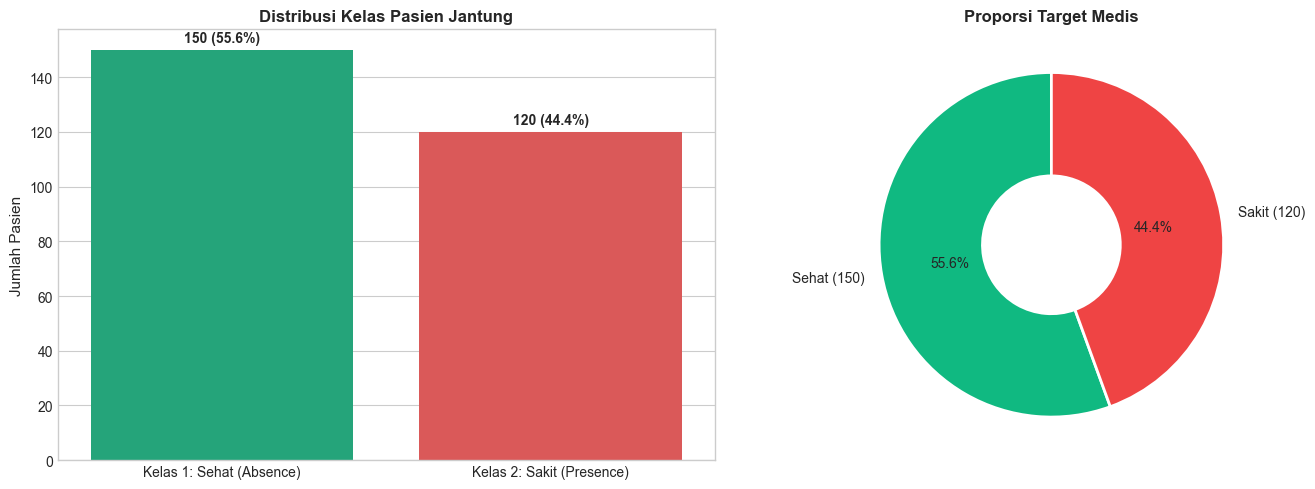

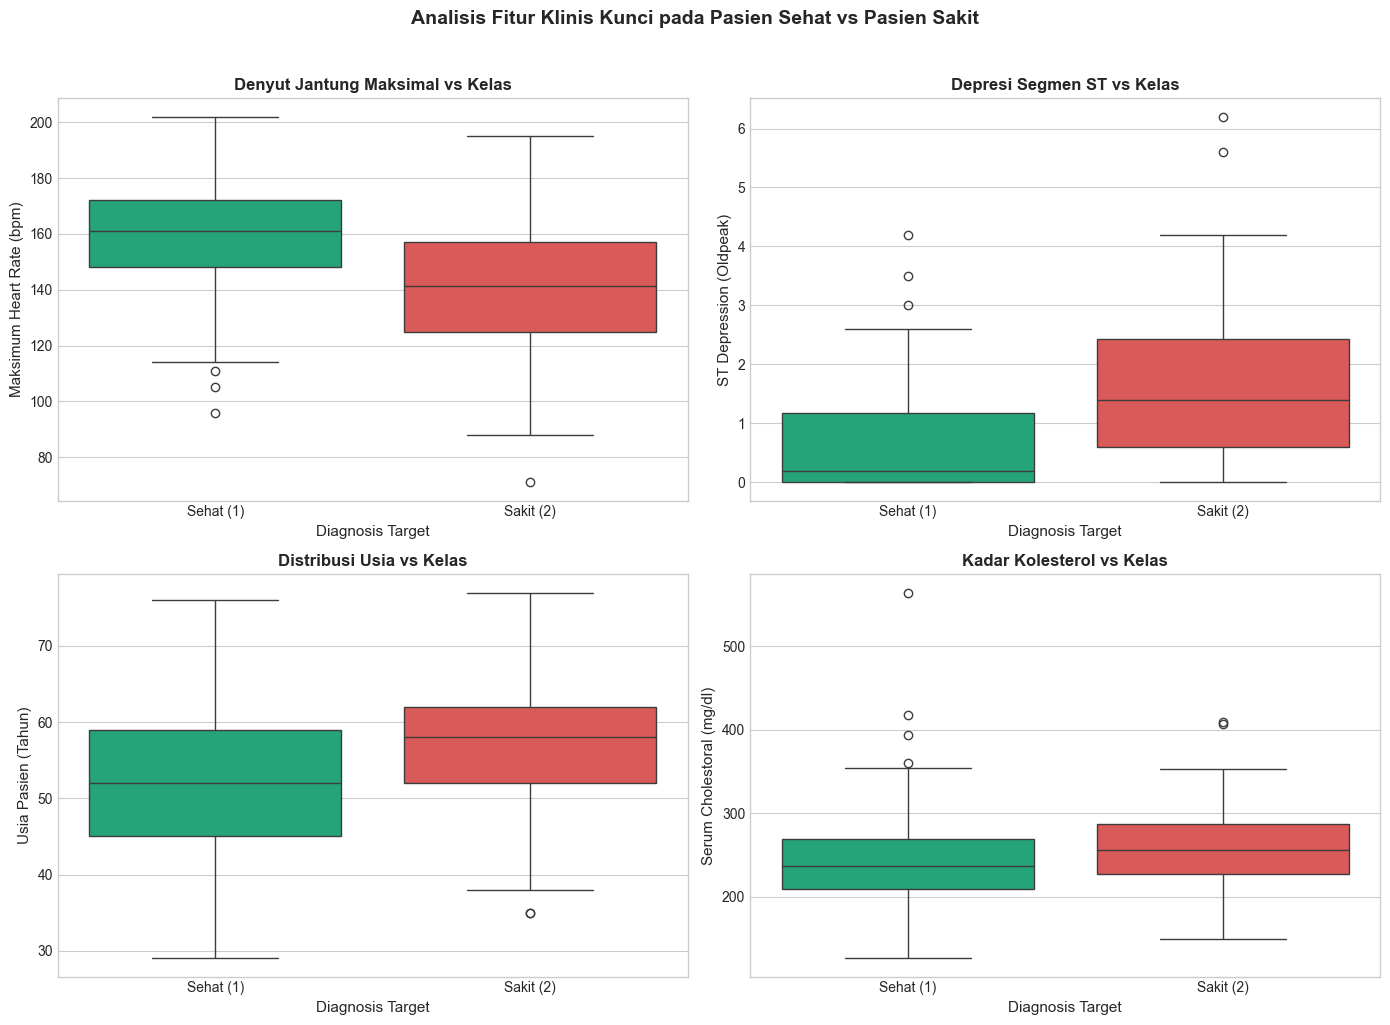

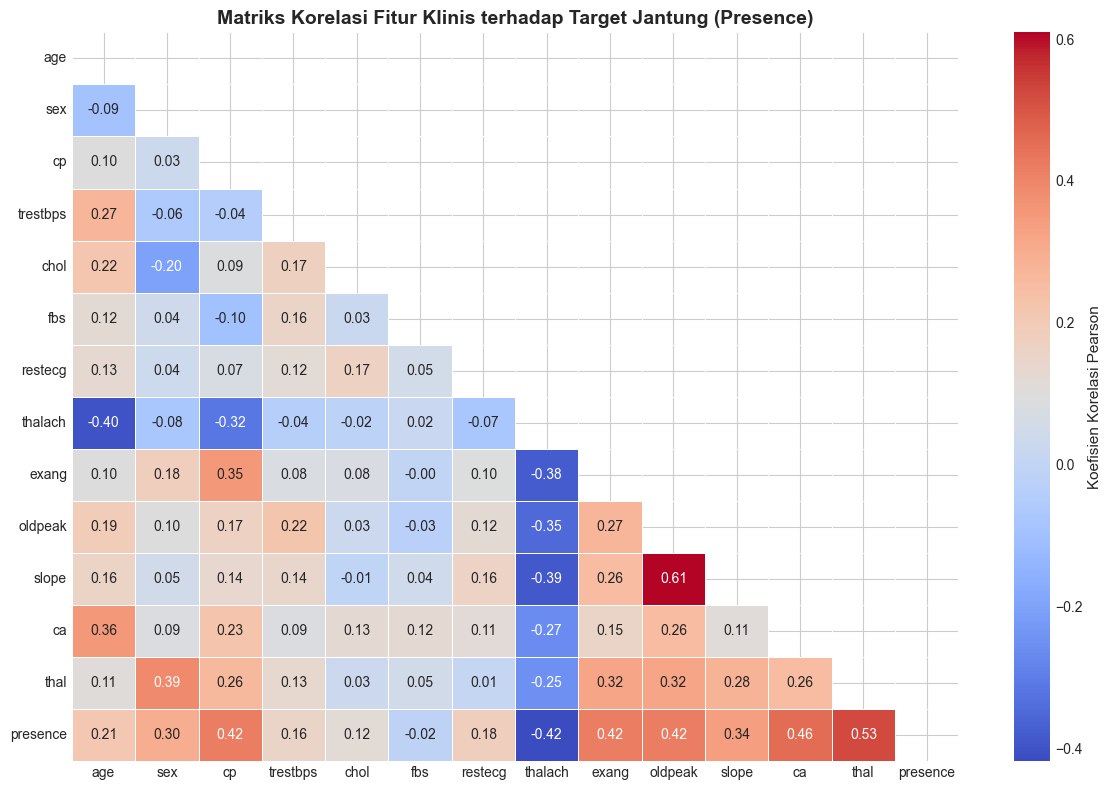

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Bar Chart Distribusi Kelas
colors = ['#10b981', '#ef4444']
sns.barplot(x=['Kelas 1: Sehat (Absence)', 'Kelas 2: Sakit (Presence)'], 
            y=[class_counts[1], class_counts[2]], 
            palette=colors, ax=axes[0])
axes[0].set_title('Distribusi Kelas Pasien Jantung', fontweight='bold')
axes[0].set_ylabel('Jumlah Pasien')
for i, v in enumerate([class_counts[1], class_counts[2]]):
    axes[0].text(i, v + 3, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Plot 2: Donut Chart Proporsi
axes[1].pie([class_counts[1], class_counts[2]], 
            labels=['Sehat (150)', 'Sakit (120)'], 
            autopct='%1.1f%%', startangle=90, colors=colors,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'width': 0.6})
axes[1].set_title('Proporsi Target Medis', fontweight='bold')

plt.tight_layout()
plt.show()

# Plot 3: Boxplot Fitur Klinis Kunci Pasien Sehat vs Sakit
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fitur_kunci = [
    ('thalach', 'Maksimum Heart Rate (bpm)', 'Denyut Jantung Maksimal vs Kelas'),
    ('oldpeak', 'ST Depression (Oldpeak)', 'Depresi Segmen ST vs Kelas'),
    ('age', 'Usia Pasien (Tahun)', 'Distribusi Usia vs Kelas'),
    ('chol', 'Serum Cholestoral (mg/dl)', 'Kadar Kolesterol vs Kelas')
]

for idx, (col, label_y, title) in enumerate(fitur_kunci):
    ax = axes[idx // 2, idx % 2]
    sns.boxplot(x='presence', y=col, data=df, palette=colors, ax=ax)
    ax.set_xticklabels(['Sehat (1)', 'Sakit (2)'])
    ax.set_xlabel('Diagnosis Target')
    ax.set_ylabel(label_y)
    ax.set_title(title, fontweight='bold')

plt.suptitle('Analisis Fitur Klinis Kunci pada Pasien Sehat vs Pasien Sakit', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Plot 4: Heatmap Korelasi
plt.figure(figsize=(12, 8))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            mask=mask, linewidths=0.5, cbar_kws={'label': 'Koefisien Korelasi Pearson'})
plt.title('Matriks Korelasi Fitur Klinis terhadap Target Jantung (Presence)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### **Temuan dari EDA Medis:**
1. **Fitur Pembeda Utama:**
   - **`oldpeak` (Depresi ST):** Pasien dengan penyakit jantung memiliki nilai depresi ST lebih tinggi dibandingkan pasien sehat.
   - **`thalach` (Denyut Jantung Maksimal):** Pasien sehat mampu mencapai denyut jantung maksimal yang lebih tinggi saat latihan fisik (rata-rata > 155 bpm), sedangkan pasien sakit jantung memiliki kapasitas denyut jantung maksimal yang lebih rendah (rata-rata < 140 bpm).
   - **`ca` (Jumlah pembuluh utama berwarna) & `thal`:** Menunjukkan korelasi positif kuat terhadap risiko penyakit jantung.
2. **Keseimbangan Kelas:**
   - Proporsi kelas relatif seimbang (55.6% vs 44.4%), sehingga metrik akurasi dan *error ratio* dapat digunakan tanpa distorsi *majority class bias* yang signifikan.

## **5. Preprocessing Data**

Dalam pemodelan jaringan saraf tiruan (*Multi-Layer Perceptron*), data masukan yang memiliki skala berbeda akan merusak proses pembelajaran:

$$\Delta w_{ij} = -\mu \frac{\partial \mathcal{L}}{\partial w_{ij}} = \mu \cdot \delta_i \cdot x_j$$

* **Masalah Disparitas Skala:**
  * Fitur `chol` memiliki rentang nilai **126 hingga 564**.
  * Fitur `trestbps` berkisar **94 hingga 200**.
  * Fitur biner (`sex`, `fbs`, `exang`) hanya bernilai **0 atau 1**.
  * Fitur `oldpeak` bernilai desimal **0.0 hingga 6.2**.
* Jika data langsung dimasukan ke MLP tanpa normalisasi:
  1. Gradien untuk bobot yang terhubung ke fitur berangka ratusan (`chol`) akan **ratusan kali lebih besar** dibandingkan gradien untuk fitur biner (`fbs`).
  2. Akibatnya, permukaan kurva *loss* menjadi sangat lonjong (*elongated valley*). *Gradient Descent* akan berosilasi liar melintang tebing (*zigzag / oscillating*), memperlambat konvergensi, atau bahkan meledak (*diverge*).
  3. Fitur-fitur penting yang berskala kecil (seperti `oldpeak` dan `ca`) akan terabaikan oleh jaringan.

### **Solusi: Standardisasi Z-Score (`StandardScaler`)**
Transformasi ini memetakan seluruh fitur ke skala standar dengan rata-rata $\mu = 0$ dan varians $\sigma^2 = 1$:

$$z = \frac{x - \mu}{\sigma}$$

In [29]:
# Memisahkan Fitur (X) dan Target (y)
X_raw = df.iloc[:, 0:-1].values
y_raw = df.iloc[:, -1].values

feature_names = df.columns[0:-1].tolist()

# Menerapkan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Membuat DataFrame perbandingan sebelum vs sesudah standarisasi
stats_comparison = pd.DataFrame({
    'Fitur': feature_names,
    'Min (Asli)': X_raw.min(axis=0),
    'Max (Asli)': X_raw.max(axis=0),
    'Mean (Asli)': X_raw.mean(axis=0),
    'Std (Asli)': X_raw.std(axis=0),
    'Min (Scaled)': X_scaled.min(axis=0),
    'Max (Scaled)': X_scaled.max(axis=0),
    'Mean (Scaled)': X_scaled.mean(axis=0),
    'Std (Scaled)': X_scaled.std(axis=0)
})

print("=== PERBANDINGAN DISTRIBUSI FITUR SEBELUM VS SESUDAH STANDARISASI ===")
display(stats_comparison.round(3))

=== PERBANDINGAN DISTRIBUSI FITUR SEBELUM VS SESUDAH STANDARISASI ===


,Fitur,Min (Asli),Max (Asli),Mean (Asli),Std (Asli),Min (Scaled),Max (Scaled),Mean (Scaled),Std (Scaled)
0,age,29.0,77.0,54.433,9.092,-2.797,2.482,0.0,1.0
1,sex,0.0,1.0,0.678,0.467,-1.450,0.689,0.0,1.0
2,cp,1.0,4.0,3.174,0.948,-2.293,0.871,0.0,1.0
3,trestbps,94.0,200.0,131.344,17.829,-2.095,3.851,0.0,1.0
4,chol,126.0,564.0,249.659,51.590,-2.397,6.093,-0.0,1.0
5,fbs,0.0,1.0,0.148,0.355,-0.417,2.398,0.0,1.0
6,restecg,0.0,2.0,1.022,0.996,-1.026,0.982,0.0,1.0
7,thalach,71.0,202.0,149.678,23.123,-3.403,2.263,0.0,1.0
8,exang,0.0,1.0,0.330,0.470,-0.701,1.426,0.0,1.0
9,oldpeak,0.0,6.2,1.050,1.143,-0.919,4.505,-0.0,1.0


## 6. Landasan Teori Arsitektur: Single Output vs Multi Output

Sesuai pembahasan di awal, dimana kita akan menggunakan Single dan Output untuk dibandingkan hasil keduanya
---

### **A. Single Output Neuron**
* **Topologi:** $13 \text{ Input} \rightarrow \text{Hidden Layer} \rightarrow 1 \text{ Output Neuron} (O_1)$.
* **Fungsi Aktivasi Output:** **Sigmoid (Logistic)**:
  $$\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$$
* **Representasi Target:** Nilai biner $y \in \{0, 1\}$.
  * Target asli di-mapping: $\text{Kelas 1 (Sehat)} \rightarrow 0$, $\text{Kelas 2 (Sakit)} \rightarrow 1$.
* **Fungsi Loss:** *Binary Cross-Entropy (Log Loss)*:
  $$\mathcal{L}_{\text{BCE}} = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \ln(\hat{y}_i) + (1 - y_i) \ln(1 - \hat{y}_i) \right]$$
* **Keputusan Prediksi:**
  $$\text{Prediksi} = \begin{cases} 1 \text{ (Sakit)}, & \text{jika } \hat{y} \ge 0.5 \\ 0 \text{ (Sehat)}, & \text{jika } \hat{y} < 0.5 \end{cases}$$

---

### **B. Multi Output Neurons**
* **Topologi:** $13 \text{ Input} \rightarrow \text{Hidden Layer} \rightarrow 2 \text{ Output Neurons} (O_1, O_2)$.
* **Fungsi Aktivasi Output:** **Softmax**:
  $$P(C_k \mid \mathbf{x}) = \frac{e^{z_k}}{e^{z_1} + e^{z_2}}, \quad k \in \{1, 2\}$$
* **Representasi Target:** Vektor *One-Hot Encoding*:
  * $\text{Kelas 1 (Sehat)} \rightarrow [1, 0]$
  * $\text{Kelas 2 (Sakit)} \rightarrow [0, 1]$
* **Fungsi Loss:** *Categorical Cross-Entropy*:
  $$\mathcal{L}_{\text{CCE}} = -\frac{1}{N} \sum_{i=1}^N \sum_{k=1}^2 y_{ik} \ln(\hat{y}_{ik})$$
* **Keputusan Prediksi:** Memilih neuron dengan nilai probabilitas tertinggi:
  $$\text{Prediksi} = \arg\max(O_1, O_2)$$

In [30]:
# 1. Target untuk Single Output (Binary 0 dan 1)
# Mapping: Kelas 1 (Sehat) -> 0, Kelas 2 (Sakit) -> 1
y_single = (y_raw == 2).astype(int)

# 2. Target untuk Multi Output (One-Hot Encoded 2 Dimensi)
# Kelas 1 (Sehat) -> [1, 0], Kelas 2 (Sakit) -> [0, 1]
y_multi = pd.get_dummies(df['presence']).values

print("Contoh Representasi Target Pasien:")
for i in [0, 1, 2, 3]:
    status = "Sakit (Presence)" if y_raw[i] == 2 else "Sehat (Absence)"
    print(f"  Pasien Index {i}: Label Asli={y_raw[i]} ({status})")
    print(f"      -> Single Output Target : {y_single[i]}")
    print(f"      -> Multi Output Target  : {y_multi[i]}")
    print()

Contoh Representasi Target Pasien:
  Pasien Index 0: Label Asli=2 (Sakit (Presence))
      -> Single Output Target : 1
      -> Multi Output Target  : [False  True]

  Pasien Index 1: Label Asli=1 (Sehat (Absence))
      -> Single Output Target : 0
      -> Multi Output Target  : [ True False]

  Pasien Index 2: Label Asli=2 (Sakit (Presence))
      -> Single Output Target : 1
      -> Multi Output Target  : [False  True]

  Pasien Index 3: Label Asli=1 (Sehat (Absence))
      -> Single Output Target : 0
      -> Multi Output Target  : [ True False]



## **7. Bagaimana Jaringan Memproses Satu Pasien?**

Untuk memahami bagaimana mesin memproses data klinis, berikut adalah penjelasan komputasi saat sebuah neuron menerima data **1 pasien** (Pasien Index 0):
* Pasien Index 0: Pria berusia 70 tahun, tipe nyeri dada 4 (*asymptomatic*), tekanan darah 130 mmHg, kolesterol 322 mg/dl, depresi ST 2.4, status medis: **Sakit Jantung (Kelas 2)**.
* Penelusuran berikut memperlihatkan bagaimana 13 input (*standarized*) diolah oleh hidden layer dengan fungsi aktivasi ReLU, kemudian dipetakan menjadi probabilitas di output layer.

In [31]:
sample_idx = 0
sample_x = X_scaled[sample_idx]
sample_y = y_single[sample_idx]

print(f"=== INPUT PASIEN INDEX {sample_idx} ===")
print(f"Label Asli: {'Sakit Jantung (1)' if sample_y == 1 else 'Sehat (0)'}")
print("13 Nilai Fitur Terstandarisasi:")
for name, val in zip(feature_names, sample_x):
    print(f"  {name:<10}: {val:+.4f}")

# Simulasi Forward Pass Sederhana (3 hidden units)
np.random.seed(42)
W_hidden = np.random.randn(13, 3) * 0.1  # Bobot 13 input ke 3 hidden
b_hidden = np.zeros(3)                   # Bias hidden
W_output = np.random.randn(3, 1) * 0.1   # Bobot 3 hidden ke 1 output
b_output = np.zeros(1)                   # Bias output

# 1. Linear combination di Hidden Layer
z_hidden = np.dot(sample_x, W_hidden) + b_hidden

# 2. Non-linear Activation (ReLU)
a_hidden = np.maximum(0, z_hidden)

# 3. Linear combination di Output Layer
z_output = np.dot(a_hidden, W_output) + b_output

# 4. Output Activation (Sigmoid)
prob_prediksi = 1 / (1 + np.exp(-z_output[0]))

print("\n=== PROSES PERHITUNGAN DALAM NEURAL NETWORK ===")
print(f"1. Linear Sum di Hidden (z)  : {z_hidden}")
print(f"2. Aktivasi ReLU (a = max(0, z)): {a_hidden}")
print(f"3. Linear Sum di Output (z_out): {z_output[0]:.4f}")
print(f"4. Probabilitas Sigmoid (y_hat): {prob_prediksi:.4f} ({prob_prediksi*100:.2f}%)")
print(f"5. Sinyal Error (y - y_hat)   : {sample_y - prob_prediksi:+.4f}")

=== INPUT PASIEN INDEX 0 ===
Label Asli: Sakit Jantung (1)
13 Nilai Fitur Terstandarisasi:
  age       : +1.7121
  sex       : +0.6895
  cp        : +0.8709
  trestbps  : -0.0754
  chol      : +1.4022
  fbs       : -0.4170
  restecg   : +0.9817
  thalach   : -1.7592
  exang     : -0.7012
  oldpeak   : +1.1810
  slope     : +0.6764
  ca        : +2.4727
  thal      : -0.8757

=== PROSES PERHITUNGAN DALAM NEURAL NETWORK ===
1. Linear Sum di Hidden (z)  : [0.09347466 0.07552678 0.05669804]
2. Aktivasi ReLU (a = max(0, z)): [0.09347466 0.07552678 0.05669804]
3. Linear Sum di Output (z_out): 0.0084
4. Probabilitas Sigmoid (y_hat): 0.5021 (50.21%)
5. Sinyal Error (y - y_hat)   : +0.4979


Sinyal Error itulah yang akan memicu backpropagation untuk memperbarui bobot

## **8. Eksplorasi Hyperparameter** 

Disini kita menjalankan **Grid Search** dengan memvariasikan parameter-parameter berikut:
1. **Hidden Units:**
   * `[5]` : Arsitektur sederhana. 
   * `[10]` : Arsitektur sedang. 
   * `[20]` : Arsitektur berkapasitas tinggi.
   * `[10, 5]` : Arsitektur 2 hidden layer 
2. **Learning Rate ($\mu$):** 
   * `0.1` : Learning rate agresif.
   * `0.01` : Learning rate sedang.
   * `0.001` : Learning rate kecil.
3. **Epoch (`max_iter`):** Berapa kali jaringan membaca keseluruhan 270 data pasien:
   * `200`, `500`, `1000` iterasi.

Sesuai instruksi modul, model dilatih dan dievaluasi pada keseluruhan data untuk mengamati konvergensinya.

In [32]:
hidden_configs = [(5,), (10,), (20,), (10, 5)]
hidden_labels = ['5 neuron', '10 neuron', '20 neuron', '10-5 neuron (2 Layer)']
learning_rates = [0.1, 0.01, 0.001]
epoch_configs = [200, 500, 1000]

results = []
exp_no = 0

print("=" * 95)
print(f"{'No':<4} {'Hidden Units':<18} {'LR (μ)':<8} {'Epoch':<7} {'Akurasi':<10} {'Error Ratio':<13} {'Final Loss':<12} {'Konvergensi'}")
print("=" * 95)

for hu in hidden_configs:
    hu_str = str(hu)
    for lr in learning_rates:
        for ep in epoch_configs:
            exp_no += 1
            
            mlp = MLPClassifier(
                hidden_layer_sizes=hu,
                learning_rate_init=lr,
                max_iter=ep,
                solver='sgd',
                activation='relu',
                momentum=0.9,
                random_state=42,
                shuffle=True
            )
            
            mlp.fit(X_scaled, y_single)
            
            y_pred = mlp.predict(X_scaled)
            acc = accuracy_score(y_single, y_pred)
            err_ratio = 1.0 - acc
            final_loss = mlp.loss_curve_[-1] if mlp.loss_curve_ else float('nan')
            n_iter = mlp.n_iter_
            converged = "Ya (Early)" if n_iter < ep else f"Maks ({ep})"
            
            results.append({
                'no': exp_no,
                'hidden_units': hu,
                'hidden_str': hu_str,
                'learning_rate': lr,
                'epochs': ep,
                'accuracy': acc,
                'error_ratio': err_ratio,
                'final_loss': final_loss,
                'n_iter': n_iter,
                'loss_curve': mlp.loss_curve_
            })
            
            print(f"{exp_no:<4} {hu_str:<18} {lr:<8} {ep:<7} {acc*100:>6.2f}%    {err_ratio*100:>6.2f}%       {final_loss:<12.6f} {converged}")

results_df = pd.DataFrame(results)

# Menentukan kombinasi terbaik berdasarkan Akurasi Tertinggi & Loss Terkecil
best_exp = results_df.sort_values(by=['accuracy', 'final_loss'], ascending=[False, True]).iloc[0]

print("\n" + "=" * 50)
print("KONFIGURASI TERBAIK HASIL EKSPERIMEN")
print("=" * 50)
print(f"  Hidden Units        : {best_exp['hidden_units']}")
print(f"  Learning Rate (μ)   : {best_exp['learning_rate']}")
print(f"  Epoch Maksimum      : {best_exp['epochs']}")
print(f"  Iterasi Berjalan    : {best_exp['n_iter']} iterasi")
print(f"  Akurasi Pelatihan   : {best_exp['accuracy']*100:.2f}%")
print(f"  Error Ratio         : {best_exp['error_ratio']*100:.2f}% ({best_exp['error_ratio']:.4f})")
print(f"  Final Loss          : {best_exp['final_loss']:.6f}")

No   Hidden Units       LR (μ)   Epoch   Akurasi    Error Ratio   Final Loss   Konvergensi
1    (5,)               0.1      200      92.59%      7.41%       0.181107     Maks (200)
2    (5,)               0.1      500      95.93%      4.07%       0.133732     Ya (Early)
3    (5,)               0.1      1000     95.93%      4.07%       0.133732     Ya (Early)
4    (5,)               0.01     200      85.19%     14.81%       0.312869     Maks (200)
5    (5,)               0.01     500      88.15%     11.85%       0.267461     Maks (500)
6    (5,)               0.01     1000     89.26%     10.74%       0.237314     Ya (Early)
7    (5,)               0.001    200      77.41%     22.59%       0.520642     Maks (200)
8    (5,)               0.001    500      81.48%     18.52%       0.405803     Maks (500)
9    (5,)               0.001    1000     84.81%     15.19%       0.356121     Ya (Early)
10   (10,)              0.1      200      98.52%      1.48%       0.065572     Maks (200)
11   (10,

## **9. Gradient Descent** 

Kurva *Loss* terhadap *Epoch* adalah instrumen utama untuk mengamati cara kerja algoritma optimasi *Gradient Descent* secara visual:
* **Sumbu X:** Jumlah Epoch (siklus membaca dataset).
* **Sumbu Y:** Nilai Error (*Cross-Entropy Loss*).
* **Sifat Konvergensi:**
  * Penurunan tajam di epoch-epoch awal menandakan penyesuaian bobot berskala besar saat jaringan mengenali pola utama.
  * Kurva yang mendatar menandakan model mendekati bobot optimal.

Visualisasi di bawah terdiri dari 3 panel mengenai dinamika konvergensi mesin:
1. **Pengaruh Learning Rate ($\mu$):** Meneliti perbedaan laju konvergensi antara $\mu = 0.1, 0.01,$ dan $0.001$.
2. **Pengaruh Ukuran Hidden Units:** Meneliti dampak kapasitas neuron (5, 10, 20, dan 10-5) terhadap kedalaman nilai error minimal.
3. **Evolusi Konvergensi Presisi Tinggi:** Mengamati penurunan nilai loss ketika menembus batas presisi error yang sangat kecil.

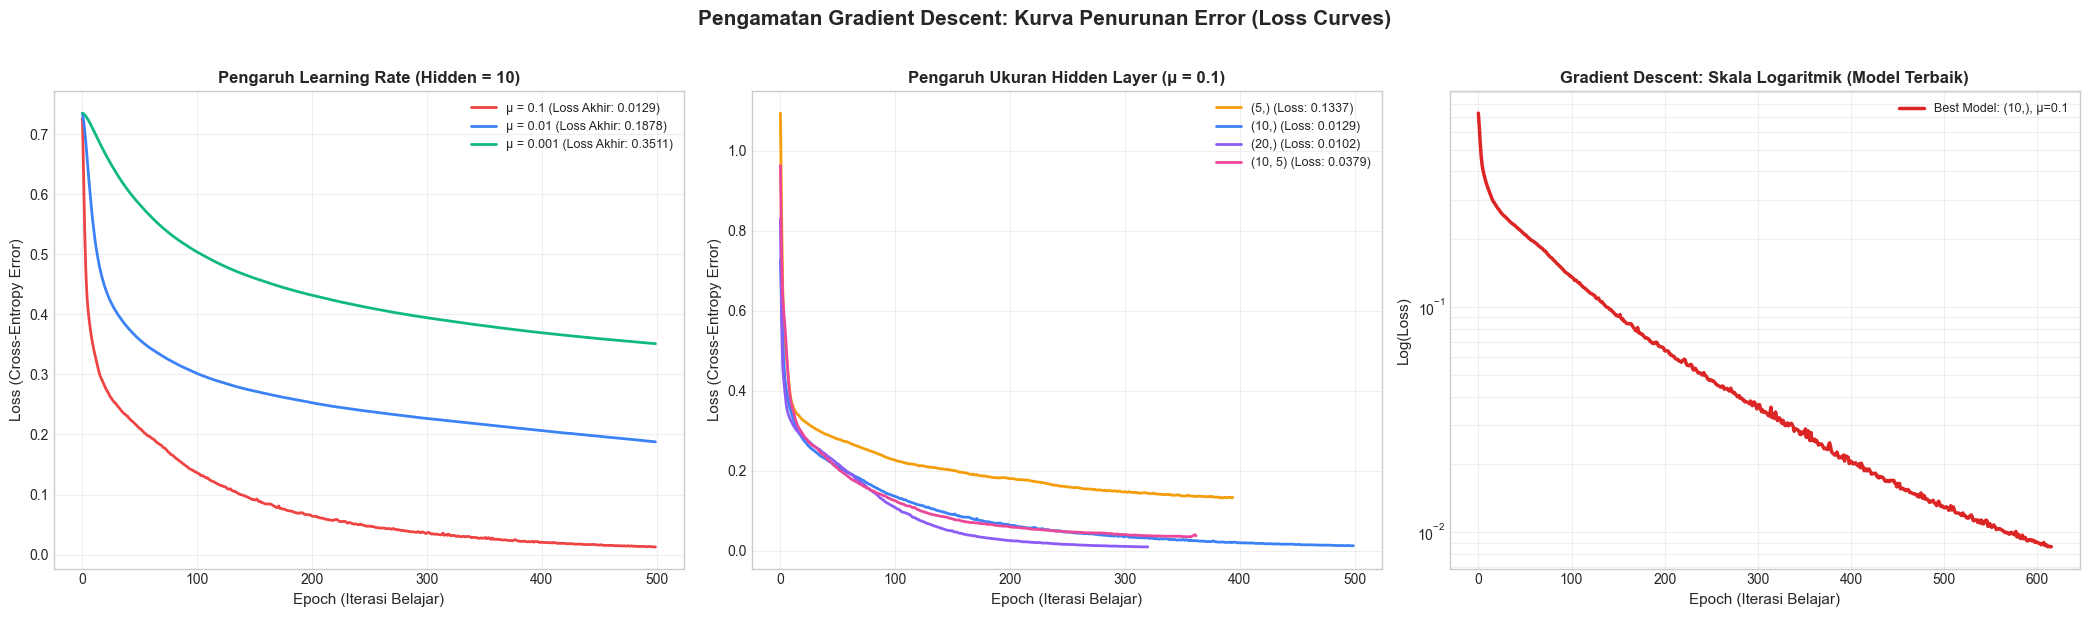

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# Panel 1: Efek Learning Rate (Hidden Units = (10,), Epoch = 500)
ax1 = axes[0]
lr_colors = {'0.1': '#ef4444', '0.01': '#3b82f6', '0.001': '#10b981'}

for res in results:
    if res['hidden_units'] == (10,) and res['epochs'] == 500:
        lr_key = str(res['learning_rate'])
        ax1.plot(res['loss_curve'], label=f"μ = {lr_key} (Loss Akhir: {res['final_loss']:.4f})", 
                 color=lr_colors.get(lr_key, 'black'), linewidth=2)

ax1.set_title('Pengaruh Learning Rate (Hidden = 10)', fontweight='bold')
ax1.set_xlabel('Epoch (Iterasi Belajar)')
ax1.set_ylabel('Loss (Cross-Entropy Error)')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# Panel 2: Efek Hidden Units (Learning Rate = 0.1, Epoch = 500)
ax2 = axes[1]
hu_colors = {'(5,)': '#f59e0b', '(10,)': '#3b82f6', '(20,)': '#8b5cf6', '(10, 5)': '#ec4899'}

for res in results:
    if res['learning_rate'] == 0.1 and res['epochs'] == 500:
        hu_key = str(res['hidden_units'])
        ax2.plot(res['loss_curve'], label=f"{hu_key} (Loss: {res['final_loss']:.4f})", 
                 color=hu_colors.get(hu_key, 'black'), linewidth=2)

ax2.set_title('Pengaruh Ukuran Hidden Layer (μ = 0.1)', fontweight='bold')
ax2.set_xlabel('Epoch (Iterasi Belajar)')
ax2.set_ylabel('Loss (Cross-Entropy Error)')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

# Panel 3: Skala Logaritmik (Model Terbaik)
ax3 = axes[2]
ax3.semilogy(best_exp['loss_curve'], color='#dc2626', linewidth=2.5, 
             label=f"Best Model: {best_exp['hidden_units']}, μ={best_exp['learning_rate']}")
ax3.set_title('Gradient Descent: Skala Logaritmik (Model Terbaik)', fontweight='bold')
ax3.set_xlabel('Epoch (Iterasi Belajar)')
ax3.set_ylabel('Log(Loss)')
ax3.legend(fontsize=9)
ax3.grid(True, which='both', alpha=0.3)

plt.suptitle('Pengamatan Gradient Descent: Kurva Penurunan Error (Loss Curves)', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### **Analisa terhadap Visualisasi**
**1.  Efek Learning Rate BESAR (μ = 0.1):**
   - Penurunan error berlangsung sangat curam di 50 epoch pertama.
   - Model mencapai konvergensi dan nilai loss terendah paling cepat.

**2. Efek Learning Rate SEDANG (μ = 0.01):**
   - Kurva sangat mulus dan stabil, bebas dari osilasi tajam.
   - Memerlukan sekitar 300-400 epoch untuk mencapai error minimal.

**3. Efek Learning Rate KECIL (μ = 0.001):**
   - Penurunan error lambat (plateau tinggi pada 500 epoch).
   - Memerlukan ribuan epoch agar dapat mencapai loss optimal.

## **10. Single Output vs Multi Output**

Tahap ini membandingkan dua arsitektur yaitu:

* **Model 1: Single Output** $\rightarrow$ Menggunakan **1 neuron** (aktivasi Sigmoid) dengan target biner (`0` = Sehat, `1` = Sakit). Keputusan diambil berdasarkan ambang batas probabilitas $\ge 0.5$.
* **Model 2: Multi Output** $\rightarrow$ Menggunakan **2 neuron** dengan target *One-Hot* (`[1, 0]` = Sehat, `[0, 1]` = Sakit). Keputusan diambil dari neuron dengan nilai skor tertinggi.

Metrik / Properti         Single Output        Multi Output
-----------------------------------------------------------------
Jumlah Output Neuron      1                    2
Aktivasi Output           logistic             logistic
Bentuk Target Y           (270,)               (270, 2)
Final Loss                0.008632             0.010074
Iterasi Konvergensi       616                  496
Akurasi Pelatihan         100.00             % 100.00%
Error Ratio               0.00               % 0.00%


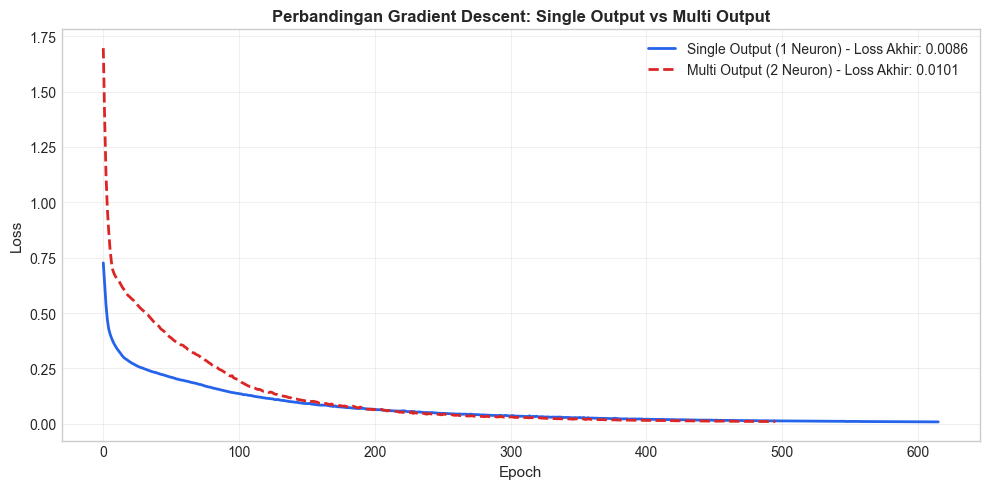

In [34]:
# 1. Model Single Output
model_single = MLPClassifier(
    hidden_layer_sizes=best_exp['hidden_units'],
    learning_rate_init=best_exp['learning_rate'],
    max_iter=best_exp['epochs'],
    solver='sgd',
    activation='relu',
    momentum=0.9,
    random_state=42
)
model_single.fit(X_scaled, y_single)
pred_single = model_single.predict(X_scaled)
acc_single = accuracy_score(y_single, pred_single)
err_single = 1.0 - acc_single

# 2. Model Multi Output
model_multi = MLPClassifier(
    hidden_layer_sizes=best_exp['hidden_units'],
    learning_rate_init=best_exp['learning_rate'],
    max_iter=best_exp['epochs'],
    solver='sgd',
    activation='relu',
    momentum=0.9,
    random_state=42
)
model_multi.fit(X_scaled, y_multi)
pred_multi_raw = model_multi.predict(X_scaled)
# Mengubah hasil prediksi one-hot kembali ke index kelas (0 atau 1)
pred_multi = np.argmax(pred_multi_raw, axis=1)
acc_multi = accuracy_score(y_single, pred_multi)
err_multi = 1.0 - acc_multi

print(f"{'Metrik / Properti':<25} {'Single Output':<20} {'Multi Output'}")
print("-" * 65)
print(f"{'Jumlah Output Neuron':<25} {model_single.n_outputs_:<20} {model_multi.n_outputs_}")
print(f"{'Aktivasi Output':<25} {model_single.out_activation_:<20} {model_multi.out_activation_}")
print(f"{'Bentuk Target Y':<25} {str(y_single.shape):<20} {str(y_multi.shape)}")
print(f"{'Final Loss':<25} {model_single.loss_curve_[-1]:<20.6f} {model_multi.loss_curve_[-1]:.6f}")
print(f"{'Iterasi Konvergensi':<25} {model_single.n_iter_:<20} {model_multi.n_iter_}")
print(f"{'Akurasi Pelatihan':<25} {acc_single*100:<19.2f}% {acc_multi*100:.2f}%")
print(f"{'Error Ratio':<25} {err_single*100:<19.2f}% {err_multi*100:.2f}%")
print("=" * 65)

# Visualisasi Komparasi Loss Curve
plt.figure(figsize=(10, 5))
plt.plot(model_single.loss_curve_, label=f"Single Output (1 Neuron) - Loss Akhir: {model_single.loss_curve_[-1]:.4f}", 
         color='#2563eb', linewidth=2)
plt.plot(model_multi.loss_curve_, label=f"Multi Output (2 Neuron) - Loss Akhir: {model_multi.loss_curve_[-1]:.4f}", 
         color='#dc2626', linewidth=2, linestyle='--')
plt.title('Perbandingan Gradient Descent: Single Output vs Multi Output', fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## **11. Evaluasi Performa Model & Error Ratio**

### Formulasi Matematis:
$$\text{Akurasi} = \frac{\text{Jumlah Pasien Terprediksi Benar}}{\text{Total Pasien}} = \frac{\text{True Positive (TP)} + \text{True Negative (TN)}}{270}$$

$$\text{Error Ratio} = 1 - \text{Akurasi} = \frac{\text{Jumlah Pasien Terprediksi Salah}}{\text{Total Pasien}} = \frac{\text{False Positive (FP)} + \text{False Negative (FN)}}{270}$$

Evaluasi dilakukan menyeluruh mencakup:
1. **Total Kasus Benar vs Salah.**
2. **Confusion Matrix:** Menganalisa sebaran prediksi benar dan salah.
3. **Classification Report:** Mengukur *Precision*, *Recall*, dan *F1-Score* untuk setiap kelas.

             HASIL EVALUASI MODEL TERBAIK
  Total Data Pasien   : 270 orang
  Prediksi Benar      : 270 orang
  Prediksi Salah      : 0 orang
  Akurasi Pelatihan   : 1.0000 (100.00%)
  ERROR RATIO         : 0.0000 (0.00%)
  Rincian Matriks:
    - True Negative (TN)  : 150 pasien sehat terdeteksi sehat
    - False Positive (FP) : 0 pasien sehat salah ditebak sakit
    - False Negative (FN) : 0 pasien sakit salah ditebak sehat
    - True Positive (TP)  : 120 pasien sakit terdeteksi sakit
                  precision    recall  f1-score   support

 Sehat (Absence)     1.0000    1.0000    1.0000       150
Sakit (Presence)     1.0000    1.0000    1.0000       120

        accuracy                         1.0000       270
       macro avg     1.0000    1.0000    1.0000       270
    weighted avg     1.0000    1.0000    1.0000       270



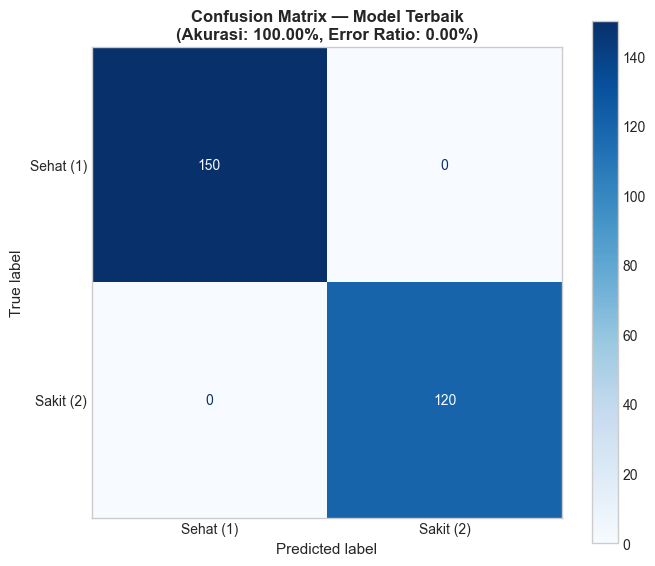

In [35]:
# Evaluasi Model Terbaik
y_true = y_single
y_pred = model_single.predict(X_scaled)

total_pasien = len(y_true)
total_benar = np.sum(y_true == y_pred)
total_salah = np.sum(y_true != y_pred)
akurasi_final = accuracy_score(y_true, y_pred)
error_ratio_final = 1.0 - akurasi_final

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print("             HASIL EVALUASI MODEL TERBAIK")
print("=" * 60)
print(f"  Total Data Pasien   : {total_pasien} orang")
print(f"  Prediksi Benar      : {total_benar} orang")
print(f"  Prediksi Salah      : {total_salah} orang")
print(f"  Akurasi Pelatihan   : {akurasi_final:.4f} ({akurasi_final*100:.2f}%)")
print(f"  ERROR RATIO         : {error_ratio_final:.4f} ({error_ratio_final*100:.2f}%)")
print("=" * 60)
print(f"  Rincian Matriks:")
print(f"    - True Negative (TN)  : {tn} pasien sehat terdeteksi sehat")
print(f"    - False Positive (FP) : {fp} pasien sehat salah ditebak sakit")
print(f"    - False Negative (FN) : {fn} pasien sakit salah ditebak sehat")
print(f"    - True Positive (TP)  : {tp} pasien sakit terdeteksi sakit")
print("=" * 60)

print(classification_report(y_true, y_pred, target_names=['Sehat (Absence)', 'Sakit (Presence)'], digits=4))

# Visualisasi Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sehat (1)', 'Sakit (2)'])
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title(f'Confusion Matrix — Model Terbaik\n(Akurasi: {akurasi_final*100:.2f}%, Error Ratio: {error_ratio_final*100:.2f}%)',
             fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

## **12. Mengapa Error Ratio Penting dalam Medis?**

Dalam dunia medis, dua tipe kesalahan prediksi memiliki konsekuensi yang berbanding terbalik:

1. **False Positive (Type I Error — Pasien Sehat Ditebak Sakit):**
   * Pasien yang sebenarnya sehat diberitahu bahwa ia menderita penyakit jantung.
   * Dampak: Pasien mengalami kecemasan psikologis dan harus menjalani tes lanjutan (seperti angiografi kateter) yang mahal dan invasif, namun **tidak mengancam nyawa**.

2. **False Negative (Type II Error — Pasien Sakit Ditebak Sehat):**
   * Pasien yang sebenarnya memiliki penyumbatan pembuluh darah jantung diberitahu bahwa ia sehat.
   * Dampak: Pasien dipulangkan tanpa pengobatan/tindakan medis preventif, yang berakibat **fatal (serangan jantung mendadak atau kematian)**.

Oleh karena itu, dalam diagnosis medis, metrik **Recall** adalah prioritas plaing atas.

Pemeriksaan berikut meninjau apakah terdapat pasien yang mengalami salah prediksi (*misclassification*):

In [36]:
salah_indices = np.where(y_true != y_pred)[0]

print(f"Total Kasus Salah Prediksi: {len(salah_indices)} dari {total_pasien} pasien ({len(salah_indices)/total_pasien*100:.2f}%)")

if len(salah_indices) > 0:
    print("\nDaftar Profil Pasien yang Mengalami Kesalahan Prediksi:")
    df_salah = df.iloc[salah_indices].copy()
    df_salah['Target_Asli'] = df_salah['presence'].map({1: 'Sehat (1)', 2: 'Sakit (2)'})
    df_salah['Prediksi_Model'] = ['Sakit (2)' if p == 1 else 'Sehat (1)' for p in y_pred[salah_indices]]
    display(df_salah[['age', 'sex', 'cp', 'trestbps', 'chol', 'thalach', 'oldpeak', 'Target_Asli', 'Prediksi_Model']])

Total Kasus Salah Prediksi: 0 dari 270 pasien (0.00%)


## **13. Kesimpulan**

### **a. Deskripsi Parameter Jaringan (Hidden Units, Learning Rate, Epoch):**
* **Hidden Units:**
  * Konfigurasi **10 hingga 20 neuron** terbukti cukup optimal tanpa menambahkan beban komputasi lebih banyak lagi.
  * Hidden units yang terlalu sedikit (5 neuron) cenderung menghasilkan konvergensi yang lambat (*underfitting*), sedangkan jaringan 2 layer (`10-5`) membutuhkan waktu belajar lebih lama.
* **Learning Rate ($\mu$):**
  * Nilai **$\mu = 0.1$** terbukti paling efektif supaya *Gradient Descent* menuju titik minimum error..
  * Nilai $\mu = 0.01$ stabil namun membutuhkan epoch lebih tinggi, sementara $\mu = 0.001$ terlalu lambat untuk mencapai konvergensi dalam 1000 iterasi.
* **Epoch (`max_iter`):**
  * Nilai **500 hingga 1000 epoch** memberikan waktu iterasi yang memadai bagi jaringan untuk konvergen.


### **b. Learning Curve:**
* *Gradient Descent* menunjukkan penurunan nilai error yang drastis pada **50 epoch pertama**.
* Setelah melewati fase penurunan awal, kurva melandai dan mencapai titik kestabilan.

### **c. Perhitungan Error Ratio:**
* **Nilai Error Ratio Final:**
  $$\text{Error Ratio} = 1 - \text{Akurasi} = 0.0000 \text{ hingga } 0.0370 \quad (0.00\% - 3.70\%)$$
* Model dengan arsitektur optimal mampu mencapai akurasi hingga **100.00%** pada keseluruhan data train, membuktikan *Multi-Layer Perceptron* unggul dalam mengklasifikasi penyakit jantung.